# Avance 1: pronóstico mensual de órdenes entrantes

**BCD5105 · Modelado matemático · III Cuatrimestre 2026 · Lead University**

**Grupo:** 2

**Integrantes:** Daniel Vasquez Gonzalez, Santiago Villareal Arley, Maria José Gonzalez Quesada, Sharis Duarte Alvarado

Este notebook reproduce el análisis exploratorio y la comparación de modelos para pronosticar las órdenes entrantes de cada mes a tres meses vista. Se comparan modelos clásicos (ingenuo, ingenuo estacional, ETS, SARIMA), los mismos con ajuste por días hábiles, una regresión Ridge, Prophet y dos modelos de fundación (Chronos-2 y TimesFM 2.5), todos con la misma validación de ventana expansiva. Al final hay una vista diaria de los datos que sirve de base para la segunda parte del proyecto (pronóstico diario a 15 días).

Se ejecuta de principio a fin en un entorno limpio de Colab (Python 3). Los datos se leen de `datos/ordenes_diarias.csv` si el archivo está junto al notebook, o del repositorio público en GitHub si no.

Contenido:
1. Configuración, versiones y semilla
2. Datos y su origen
3. Análisis exploratorio
4. Modelos y validación de ventana expansiva
5. Resultados de la validación
6. Diagnóstico del SARIMA y pronóstico de noviembre de 2026 a enero de 2027
7. Vista diaria (base para la parte 2)
8. Conclusiones

## 1. Configuración, versiones y semilla

In [1]:
%pip install -q statsforecast==2.1.1 prophet==1.5.0 chronos-forecasting==2.3.2 "timesfm[torch]==3.0.2"

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os, random, warnings, logging
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
import statsmodels, statsforecast, scipy, sklearn, prophet, torch, timesfm, chronos
from importlib.metadata import version
from scipy.stats import wilcoxon
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import acf, adfuller, kpss
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsforecast import StatsForecast
from statsforecast.models import Naive, SeasonalNaive, AutoETS, AutoARIMA
from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import TimeSeriesSplit
from prophet import Prophet
from chronos import Chronos2Pipeline

warnings.filterwarnings("ignore")
for nombre in ["cmdstanpy", "prophet"]:
    logging.getLogger(nombre).setLevel(logging.ERROR)
SEMILLA = 2026
random.seed(SEMILLA)
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)

print("pandas", pd.__version__, "| numpy", np.__version__, "| scipy", scipy.__version__, "| scikit-learn", sklearn.__version__)
print("statsmodels", statsmodels.__version__, "| statsforecast", statsforecast.__version__, "| prophet", prophet.__version__)
print("torch", torch.__version__, "| chronos-forecasting", version("chronos-forecasting"), "| timesfm", version("timesfm"))

# Estilo de las figuras: paleta categórica validada (azul, naranja, aqua), rejilla tenue, sin bordes superior/derecho
C = dict(azul="#2a78d6", naranja="#eb6834", aqua="#1baf7a", tinta="#0b0b0b", tinta2="#52514e",
         tenue="#898781", rejilla="#e1e0d9", base="#c3c2b7", fondo="#fcfcfb",
         azul_claro="#86b6ef", azul_medio="#3987e5", azul_oscuro="#1c5cab")
plt.rcParams.update({
    "figure.facecolor": C["fondo"], "axes.facecolor": C["fondo"], "axes.edgecolor": C["base"],
    "axes.labelcolor": C["tinta2"], "xtick.color": C["tenue"], "ytick.color": C["tenue"],
    "text.color": C["tinta"], "axes.grid": True, "grid.color": C["rejilla"], "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 9, "axes.titlesize": 10,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "savefig.dpi": 200,
    "savefig.bbox": "tight", "figure.dpi": 110, "legend.frameon": False})
os.makedirs("figuras", exist_ok=True)

nombres_mes = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
FMT_MES = FuncFormatter(lambda x, pos: "%s-%s" % (nombres_mes[mdates.num2date(x).month - 1], mdates.num2date(x).strftime("%y")))   # ej. ene-26

pandas 2.2.3 | numpy 2.4.6 | scipy 1.17.1 | scikit-learn 1.8.0
statsmodels 0.14.6 | statsforecast 2.1.1 | prophet 1.5.0
torch 2.12.1+cpu | chronos-forecasting 2.3.2 | timesfm 3.0.2


## 2. Datos y su origen

**Fuente:** base de datos analítica de LightForce Orthodontics (Databricks), tabla `analytics.manufacturing.mfg_all_orders`, consultada el 12 de noviembre de 2026 con autorización de la empresa. Cada fila de la tabla es un caso de manufactura. Como la base no es pública, el resultado de la consulta (conteos por día, sin datos de casos individuales) se guarda en `datos/ordenes_diarias.csv` dentro del repositorio.

**Definición de orden entrante:** caso nuevo (`order_type = 'New case'`) con fecha de recepción del escaneo (`scan_received_date`). Los _reorders_ reutilizan el escaneo original y quedan fuera. Se cuentan todos los estados, incluso casos luego cancelados, porque la demanda llegó de todos modos.

**Zona horaria:** `scan_received_date` está en UTC. Se pasa a hora de Costa Rica (UTC−6, sin horario de verano) antes de asignar el día, porque el equipo que atiende los casos y el pronóstico diario de la parte 2 están en Costa Rica. A escala mensual el cambio es pequeño (en promedio 17 órdenes por mes respecto de UTC), pero a escala diaria importa: el día laboral de Australia y Nueva Zelanda cae casi completo en el día anterior en Costa Rica (sección 7).

**Columnas del archivo:** `fecha` (día en hora de Costa Rica), `ordenes` (total), `acero` (bracket de acero inoxidable, producto lanzado en 2026) y `us`, `ca`, `au`, `nz` (órdenes por país de la cuenta; Puerto Rico se suma a EE. UU. y hay una orden de Brasil que solo cuenta en el total).

Consulta usada:

```sql
-- Órdenes nuevas por día en hora de Costa Rica (UTC-6), por país de la cuenta.
-- Fuente: analytics.manufacturing.mfg_all_orders (Databricks, LightForce).
-- scan_received_date está en UTC; se convierte a America/Costa_Rica antes de tomar la fecha.
-- Puerto Rico (PR) se suma a EE. UU.; acero = brackets de acero inoxidable.
-- Salida: ordenes_diarias.csv (fecha, ordenes, acero, us, ca, au, nz), del 2023-01-01 al 2026-11-11.
WITH o AS (
  SELECT to_date(from_utc_timestamp(scan_received_date, 'America/Costa_Rica')) AS fecha,
         CASE WHEN account_country IN ('US', 'PR') THEN 'US' ELSE account_country END AS pais,
         CASE WHEN bracket_material_name = 'Stainless Steel' THEN 1 ELSE 0 END AS acero
  FROM analytics.manufacturing.mfg_all_orders
  WHERE order_type = 'New case' AND scan_received_date IS NOT NULL
)
SELECT fecha,
       count(*) AS ordenes,
       sum(acero) AS acero,
       sum(CASE WHEN pais = 'US' THEN 1 ELSE 0 END) AS us,
       sum(CASE WHEN pais = 'CA' THEN 1 ELSE 0 END) AS ca,
       sum(CASE WHEN pais = 'AU' THEN 1 ELSE 0 END) AS au,
       sum(CASE WHEN pais = 'NZ' THEN 1 ELSE 0 END) AS nz
FROM o
WHERE fecha BETWEEN DATE'2023-01-01' AND DATE'2026-11-11'
GROUP BY fecha
ORDER BY fecha;
```

In [3]:
RUTA = "datos/ordenes_diarias.csv"
URL = "https://raw.githubusercontent.com/DannyV1992/curso_modelado/main/Tareas/Proyecto_integrador/Avance_1/datos/ordenes_diarias.csv"
diario = pd.read_csv(RUTA if os.path.exists(RUTA) else URL, parse_dates=["fecha"]).set_index("fecha")
PAISES = ["us", "ca", "au", "nz"]
assert diario.index.is_unique and len(diario) == (diario.index[-1] - diario.index[0]).days + 1, "debe haber un registro por día, sin huecos"
assert (diario[PAISES].sum(axis=1) <= diario.ordenes).all() and (diario.acero <= diario.ordenes).all()
print("Días:", len(diario), "|", diario.index[0].date(), "a", diario.index[-1].date(), "| órdenes:", diario.ordenes.sum())

def dias_habiles(meses):
    """Días de lunes a viernes de cada mes (sin descontar feriados)."""
    return np.array([np.busday_count(m.date(), (m + pd.offsets.MonthBegin(1)).date()) for m in meses])

# Serie mensual: meses completos de enero de 2023 a octubre de 2026. Noviembre de 2026 está incompleto y queda aparte.
mensual = diario[:"2026-10-31"].resample("MS").sum()
mensual["resto"] = mensual.ordenes - mensual.acero
mensual["dias_habiles"] = dias_habiles(mensual.index)
serie = mensual["ordenes"].astype(float).asfreq("MS")
dh = mensual["dias_habiles"].astype(float)
assert serie.isna().sum() == 0 and len(serie) == 46
nov_parcial = diario["2026-11-01":]
print("Serie mensual:", serie.index[0].strftime("%Y-%m"), "a", serie.index[-1].strftime("%Y-%m"), "| meses:", len(serie), "| órdenes:", int(serie.sum()))
print("Noviembre de 2026 observado: %d órdenes del 1 al %d (parcial, no entra en el ajuste)" % (nov_parcial.ordenes.sum(), nov_parcial.index[-1].day))

Días: 1411 | 2023-01-01 a 2026-11-11 | órdenes: 213358
Serie mensual: 2023-01 a 2026-10 | meses: 46 | órdenes: 211325
Noviembre de 2026 observado: 2033 órdenes del 1 al 11 (parcial, no entra en el ajuste)


## 3. Análisis exploratorio

In [4]:
print(serie.describe().round(1).to_string())
print("Coeficiente de variación: %.2f" % (serie.std() / serie.mean()))
por_anio = serie.groupby(serie.index.year).agg(total="sum", promedio_mensual="mean", meses="count").round(1)
print("\nPor año (2026 incluye enero a octubre):")
print(por_anio.to_string())

# Perfil por mes del año: cada mes como proporción del promedio de su año, en los dos años completos y estables
completos = serie["2024":"2025"]
indice = (completos / completos.groupby(completos.index.year).transform("mean")).groupby(completos.index.month).mean()
print("\nÍndice mensual 2024-2025 (1.00 = promedio del año):")
print(pd.Series(indice.values.round(2), index=nombres_mes).to_string())
print("\nDías hábiles por mes: mínimo %d, máximo %d" % (dh.min(), dh.max()))

pais = mensual[PAISES].groupby(mensual.index.year).sum()
print("\nParticipación por país de la cuenta (% de las órdenes del año):")
print((100 * pais.div(pais.sum(axis=1), axis=0)).round(1).to_string())

count      46.0
mean     4594.0
std       543.8
min      3363.0
25%      4156.8
50%      4730.5
75%      4906.5
max      6039.0
Coeficiente de variación: 0.12

Por año (2026 incluye enero a octubre):
         total  promedio_mensual  meses
fecha                                  
2023   49084.0            4090.3     12
2024   55879.0            4656.6     12
2025   56647.0            4720.6     12
2026   49715.0            4971.5     10

Índice mensual 2024-2025 (1.00 = promedio del año):
ene    1.06
feb    1.02
mar    0.98
abr    1.02
may    1.01
jun    1.06
jul    1.08
ago    1.02
sep    0.96
oct    1.05
nov    0.89
dic    0.86

Días hábiles por mes: mínimo 20, máximo 23

Participación por país de la cuenta (% de las órdenes del año):
         us    ca   au   nz
fecha                      
2023   69.6  22.4  7.1  1.0
2024   66.7  22.8  9.0  1.5
2025   65.3  23.7  9.2  1.8
2026   65.5  25.0  8.4  1.1


In [5]:
# Cambio reciente: producto de acero inoxidable
print(mensual.loc["2025-12":, ["ordenes", "acero", "resto"]].assign(pct_acero=lambda x: (100 * x.acero / x.ordenes).round(1)).to_string())
previo = serie["2025-10":"2026-04"].mean()
print("Promedio mensual oct-2025 a abr-2026 (antes del auge): %.0f" % previo)
print("Promedio mensual jun-ago-2026: %.0f (%+.0f %%)" % (serie["2026-06":"2026-08"].mean(), 100 * (serie["2026-06":"2026-08"].mean() / previo - 1)))
print("Promedio sep-oct-2026: %.0f (%+.0f %%)" % (serie["2026-09":"2026-10"].mean(), 100 * (serie["2026-09":"2026-10"].mean() / previo - 1)))
print("Acero por día, 1 al 25 de octubre: %.1f | 26 de octubre al %s: %.1f (se reabrió el producto)" %
      (diario["2026-10-01":"2026-10-25"].acero.mean(), nov_parcial.index[-1].strftime("%d de noviembre"), diario["2026-10-26":].acero.mean()))

            ordenes  acero  resto  pct_acero
fecha                                       
2025-12-01     4156     11   4145        0.3
2026-01-01     4699     20   4679        0.4
2026-02-01     4687     63   4624        1.3
2026-03-01     5046    122   4924        2.4
2026-04-01     5067    353   4714        7.0
2026-05-01     4807    915   3892       19.0
2026-06-01     6039   1627   4412       26.9
2026-07-01     5700   1822   3878       32.0
2026-08-01     5462   1740   3722       31.9
2026-09-01     4099    118   3981        2.9
2026-10-01     4109    240   3869        5.8
Promedio mensual oct-2025 a abr-2026 (antes del auge): 4683
Promedio mensual jun-ago-2026: 5734 (+22 %)
Promedio sep-oct-2026: 4104 (-12 %)
Acero por día, 1 al 25 de octubre: 0.9 | 26 de octubre al 11 de noviembre: 47.2 (se reabrió el producto)


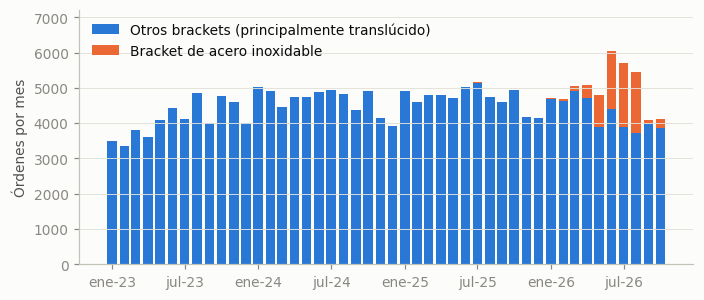

In [6]:
# Figura 1. Órdenes mensuales por tipo de bracket
fig, ax = plt.subplots(figsize=(7.2, 3.0))
ax.bar(mensual.index, mensual["resto"], width=24, color=C["azul"], label="Otros brackets (principalmente translúcido)")
ax.bar(mensual.index, mensual["acero"], width=24, bottom=mensual["resto"], color=C["naranja"], label="Bracket de acero inoxidable")
ax.set(ylabel="Órdenes por mes", ylim=(0, 7200))
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7])); ax.xaxis.set_major_formatter(FMT_MES)
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left", ncol=1)
fig.savefig("figuras/fig1_serie_mensual.png"); plt.show()

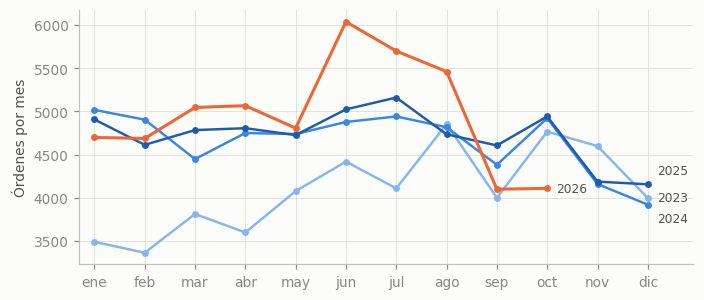

In [7]:
# Figura 2. Perfil anual: un trazo por año, para ver si el patrón por mes se repite
fig, ax = plt.subplots(figsize=(7.2, 3.0))
colores = {2023: C["azul_claro"], 2024: C["azul_medio"], 2025: C["azul_oscuro"], 2026: C["naranja"]}
for anio, g in serie.groupby(serie.index.year):
    ax.plot(g.index.month, g.values, color=colores[anio], lw=2 if anio == 2026 else 1.6, marker="o", ms=3.5)
    ax.annotate(str(anio), xy=(g.index.month[-1], g.values[-1]), xytext=(6, {2025: 9, 2023: 0, 2024: -9}.get(anio, 0)),
                textcoords="offset points", va="center", fontsize=8, color=C["tinta2"])
ax.set(ylabel="Órdenes por mes", xlim=(0.7, 12.9))
ax.set_xticks(range(1, 13)); ax.set_xticklabels(nombres_mes)
fig.savefig("figuras/fig2_perfil_anual.png"); plt.show()

Fuerza de la tendencia: 0.38 | Fuerza de la estacionalidad anual: 0.28
ACF rezago 1: 0.51 | 2: 0.32 | 6: -0.03 | 12: 0.15


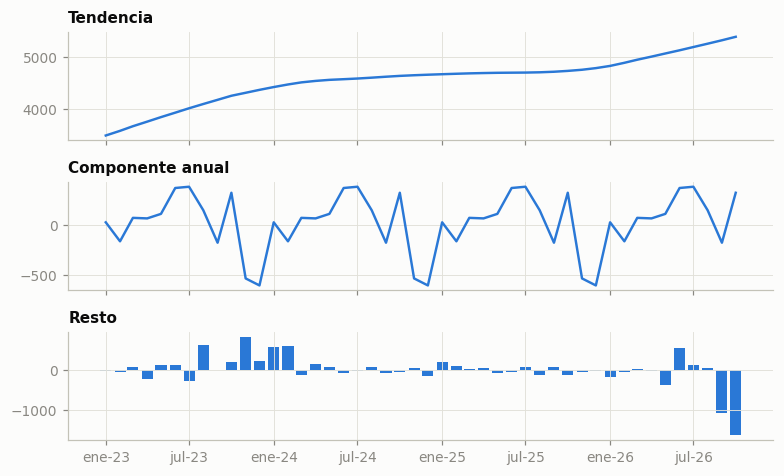

Resto de mayor magnitud: {'2026-10': -1614, '2026-09': -1058, '2023-11': 821, '2023-08': 614}


In [8]:
# Figura 3. Descomposición STL robusta con período 12 (tendencia, componente anual y resto)
# seasonal=99 con seasonal_deg=0: el componente anual es el mismo cada año, equivalente a season(window = "periodic") de fpp3
stl = STL(serie, period=12, seasonal=99, seasonal_deg=0, robust=True).fit()
Ft = max(0, 1 - np.var(stl.resid) / np.var(stl.trend + stl.resid))
Fs = max(0, 1 - np.var(stl.resid) / np.var(stl.seasonal + stl.resid))
print("Fuerza de la tendencia: %.2f | Fuerza de la estacionalidad anual: %.2f" % (Ft, Fs))
a = acf(serie, nlags=12)
print("ACF rezago 1: %.2f | 2: %.2f | 6: %.2f | 12: %.2f" % (a[1], a[2], a[6], a[12]))

fig, ax = plt.subplots(3, 1, figsize=(7.2, 4.4), sharex=True)
ax[0].plot(stl.trend, color=C["azul"], lw=1.6); ax[0].set_title("Tendencia")
ax[1].plot(stl.seasonal, color=C["azul"], lw=1.6); ax[1].set_title("Componente anual")
ax[2].bar(stl.resid.index, stl.resid.values, width=24, color=C["azul"]); ax[2].set_title("Resto")
ax[2].xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7])); ax[2].xaxis.set_major_formatter(FMT_MES)
fig.tight_layout(); fig.savefig("figuras/fig3_stl.png"); plt.show()
print("Resto de mayor magnitud:", {k.strftime("%Y-%m"): round(v) for k, v in stl.resid[stl.resid.abs().nlargest(4).index].items()})

In [9]:
# Estacionariedad: ADF (H0: raíz unitaria; p bajo = estacionaria) y KPSS (H0: estacionaria; p bajo = no estacionaria)
# Nota: statsmodels acota el p-valor de KPSS al rango [0.01, 0.10].
for etiqueta, x in [("serie original (46 meses)", serie),
                    ("diferencia estacional (1 - B^12), 34 meses", serie.diff(12).dropna()),
                    ("(1 - B)(1 - B^12), 33 meses", serie.diff(12).diff().dropna())]:
    print("%-44s ADF p = %.4f | KPSS p = %.2f" % (etiqueta, adfuller(x, autolag="AIC")[1], kpss(x, nlags="auto")[1]))

serie original (46 meses)                    ADF p = 0.0020 | KPSS p = 0.02
diferencia estacional (1 - B^12), 34 meses   ADF p = 0.0256 | KPSS p = 0.08
(1 - B)(1 - B^12), 33 meses                  ADF p = 0.0000 | KPSS p = 0.10


## 4. Modelos y validación de ventana expansiva

Todos los modelos se evalúan igual: la primera ventana entrena con enero de 2023 a diciembre de 2024 (24 meses) y pronostica los 3 meses siguientes; luego se agrega un mes por ventana hasta pronosticar agosto a octubre de 2026. Son 20 ventanas y 60 pronósticos por modelo. En cada ventana cada modelo se vuelve a ajustar solo con los meses anteriores a su origen.

| Familia | Modelo | Idea |
|---|---|---|
| Referencias | Naive, SNAIVE | Repite el último mes / el mismo mes del año anterior |
| Suavizamiento exponencial | AutoETS | Error, tendencia y estacionalidad elegidos por AICc |
| ARIMA estacional | SARIMA (AutoARIMA, m = 12) | Órdenes por pruebas de raíz unitaria y AICc |
| Ajuste por días hábiles | SNAIVE_dh, AutoETS_dh, SARIMA_dh | Se modela $y_t / d_t$ (órdenes por día hábil) y se multiplica por $d_{T+h}$ |
| Regresión | Ridge | Tendencia lineal, mes del año y días hábiles; penalización elegida con validación temporal |
| Aditivo | Prophet | Tendencia por tramos y estacionalidad anual de Fourier |
| Fundación | Chronos-2, Chronos-2 + días hábiles | Preentrenado, sin ajuste; la segunda versión recibe los días hábiles como covariable conocida |
| Fundación | TimesFM 2.5 (200M) | Preentrenado, sin ajuste |

In [10]:
H, M, INI = 3, 12, 24
datos = pd.DataFrame({"unique_id": "ordenes", "ds": serie.index, "y": serie.values})
N_VENT = len(serie) - INI - H + 1
print("Ventanas:", N_VENT, "| primer origen:", serie.index[INI - 1].strftime("%Y-%m"), "| último mes pronosticado:", serie.index[-1].strftime("%Y-%m"))

clasicos = [Naive(alias="Naive"), SeasonalNaive(season_length=M, alias="SNAIVE"),
            AutoETS(season_length=M, alias="AutoETS"), AutoARIMA(season_length=M, alias="SARIMA")]
cv = StatsForecast(models=clasicos, freq="MS", n_jobs=1).cross_validation(df=datos, h=H, step_size=1, n_windows=N_VENT, refit=True)
assert cv.cutoff.nunique() == N_VENT and cv.cutoff.min() == serie.index[INI - 1]

# Ajuste por días hábiles: el mismo modelo sobre órdenes por día hábil, y de vuelta a órdenes del mes
cv_dh = StatsForecast(models=clasicos[1:], freq="MS", n_jobs=1).cross_validation(
    df=datos.assign(y=serie.values / dh.values), h=H, step_size=1, n_windows=N_VENT, refit=True)
for nom in ["SNAIVE", "AutoETS", "SARIMA"]:
    cv[nom + "_dh"] = cv_dh[nom].values * dh.reindex(cv_dh.ds).values

Ventanas: 20 | primer origen: 2024-12 | último mes pronosticado: 2026-10


In [11]:
def X_ridge(idx):
    t = np.array([(d.year - 2023) * 12 + d.month for d in idx], float)
    mes = pd.get_dummies(pd.Categorical([d.month for d in idx], categories=range(1, 13))).values[:, 1:].astype(float)
    return np.column_stack([t, mes, dias_habiles(idx)])

def ridge_fc(tr, fut):
    m = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 30), cv=TimeSeriesSplit(4)))
    m.fit(X_ridge(tr.index), tr.values)
    return m.predict(X_ridge(fut))

def prophet_fc(tr, fut):
    m = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False)
    m.fit(pd.DataFrame({"ds": tr.index, "y": tr.values}))
    return m.predict(pd.DataFrame({"ds": fut}))["yhat"].values

chronos2 = Chronos2Pipeline.from_pretrained("amazon/chronos-2", device_map="cpu")
def chronos_fc(tr, fut, cov=False):
    ctx = pd.DataFrame({"id": "o", "timestamp": tr.index, "target": tr.values.astype(float)})
    fut_df = None
    if cov:
        ctx["dh"] = dias_habiles(tr.index).astype(float)
        fut_df = pd.DataFrame({"id": "o", "timestamp": fut, "dh": dias_habiles(fut).astype(float)})
    out = chronos2.predict_df(ctx, future_df=fut_df, prediction_length=len(fut), quantile_levels=[0.1, 0.5, 0.9],
                              id_column="id", timestamp_column="timestamp", target="target")
    return out["0.5"].values

tfm = timesfm.TimesFM_2p5_200M_torch.from_pretrained("google/timesfm-2.5-200m-pytorch")
tfm.compile(timesfm.ForecastConfig(max_context=1024, max_horizon=64, normalize_inputs=True, use_continuous_quantile_head=True,
                                   force_flip_invariance=True, infer_is_positive=True, fix_quantile_crossing=True))
def timesfm_fc(tr, fut):
    punto, _ = tfm.forecast(horizon=len(fut), inputs=[tr.values.astype(float)])
    return punto[0]

otros = {"Ridge": ridge_fc, "Prophet": prophet_fc, "Chronos2": chronos_fc,
         "Chronos2_dh": lambda tr, fut: chronos_fc(tr, fut, cov=True), "TimesFM": timesfm_fc}
for nom, f in otros.items():
    partes = [pd.Series(f(serie[:corte], pd.DatetimeIndex(g.ds)), index=g.index) for corte, g in cv.groupby("cutoff", sort=True)]
    cv[nom] = pd.concat(partes)

NOMBRES = ["Naive", "SNAIVE", "AutoETS", "SARIMA", "SNAIVE_dh", "AutoETS_dh", "SARIMA_dh",
           "Ridge", "Prophet", "Chronos2", "Chronos2_dh", "TimesFM"]
for nom in NOMBRES:
    cv[nom] = cv[nom].clip(lower=0)                                    # restricción: los conteos no son negativos
cv["h"] = cv.groupby("cutoff").cumcount() + 1
print("Pronósticos evaluados por modelo:", len(cv), "(", cv.cutoff.nunique(), "ventanas x", H, "meses )")

Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

Pronósticos evaluados por modelo: 60 ( 20 ventanas x 3 meses )


## 5. Resultados de la validación

In [12]:
def escala_mase(corte):
    """Error absoluto medio del ingenuo estacional (m = 12) dentro del entrenamiento hasta `corte`."""
    ent = serie[:corte].values
    return np.mean(np.abs(ent[M:] - ent[:-M]))

cv["esc"] = cv.cutoff.map(escala_mase)
QUIEBRE = pd.Timestamp("2026-03-01")            # orígenes desde marzo de 2026: pronostican meses con el producto de acero
mase_v = pd.DataFrame({n: ((cv.y - cv[n]).abs() / cv.esc).groupby(cv.cutoff).mean() for n in NOMBRES})   # MASE por ventana
pre = mase_v.index < QUIEBRE
filas = []
for n in NOMBRES:
    e = cv.y - cv[n]
    por_h = (e.abs() / cv.esc).groupby(cv.h).mean()
    filas.append({"modelo": n, "MAE": e.abs().mean(), "RMSE": np.sqrt((e ** 2).mean()), "MASE": mase_v[n].mean(),
                  "MASE antes mar-26": mase_v[n][pre].mean(), "MASE desde mar-26": mase_v[n][~pre].mean(),
                  "h=1": por_h[1], "h=2": por_h[2], "h=3": por_h[3],
                  "gana a SNAIVE": int((mase_v[n] < mase_v.SNAIVE).sum()) if n != "SNAIVE" else np.nan,
                  "p Wilcoxon vs SNAIVE": wilcoxon(mase_v[n], mase_v.SNAIVE).pvalue if n != "SNAIVE" else np.nan,
                  "sesgo": (cv[n] - cv.y).mean()})
tabla = pd.DataFrame(filas).set_index("modelo").sort_values("MASE")
print("Ventanas: %d en total, %d con origen antes de marzo de 2026 y %d desde marzo de 2026" % (len(mase_v), pre.sum(), (~pre).sum()))
print(tabla.round(3).to_string())
MEJOR = tabla.index[0]
print("\nMejor modelo por MASE promedio:", MEJOR)
print("%s contra SARIMA_dh: gana en %d de %d ventanas | Wilcoxon p = %.3f" %
      (MEJOR, (mase_v[MEJOR] < mase_v.SARIMA_dh).sum(), len(mase_v), wilcoxon(mase_v[MEJOR], mase_v.SARIMA_dh).pvalue))

Ventanas: 20 en total, 15 con origen antes de marzo de 2026 y 5 desde marzo de 2026
                 MAE     RMSE   MASE  MASE antes mar-26  MASE desde mar-26    h=1    h=2    h=3  gana a SNAIVE  p Wilcoxon vs SNAIVE    sesgo
modelo                                                                                                                                       
SNAIVE_dh    234.558  329.645  0.564              0.246              1.519  0.506  0.558  0.628           14.0                 0.008 -162.769
SARIMA_dh    283.453  414.594  0.633              0.426              1.252  0.419  0.613  0.866            8.0                 0.546  -48.982
SNAIVE       268.667  374.445  0.646              0.325              1.608  0.588  0.636  0.714            NaN                   NaN -153.733
SARIMA       306.823  492.002  0.700              0.392              1.621  0.513  0.708  0.877           10.0                 0.756  -48.493
Ridge        301.143  387.999  0.711              0.503         

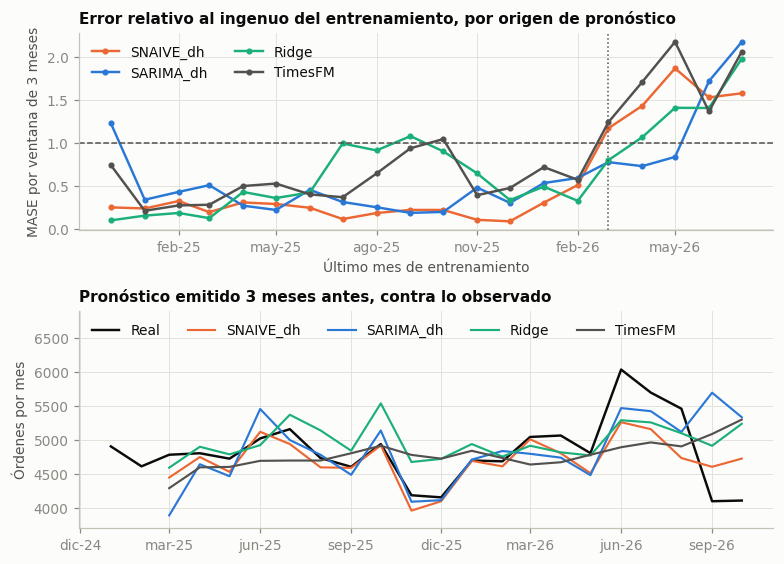

In [13]:
# Figura 4. MASE por ventana de los mejores modelos de cada familia y pronóstico emitido 3 meses antes
vista = {"SNAIVE_dh": C["naranja"], "SARIMA_dh": C["azul"], "Ridge": C["aqua"], "TimesFM": C["tinta2"]}
fig, (a1, a2) = plt.subplots(2, 1, figsize=(7.2, 5.2), gridspec_kw={"height_ratios": [1, 1.1]})
for n, col in vista.items():
    a1.plot(mase_v.index, mase_v[n], color=col, lw=1.6, marker="o", ms=3, label=n)
a1.axhline(1, color=C["tinta2"], lw=1, ls="--")
a1.axvline(QUIEBRE, color=C["tinta2"], lw=1, ls=":")
a1.set(ylabel="MASE por ventana de 3 meses", title="Error relativo al ingenuo del entrenamiento, por origen de pronóstico",
       xlabel="Último mes de entrenamiento")
a1.legend(loc="upper left", ncol=2)
a1.xaxis.set_major_locator(mdates.MonthLocator(interval=3)); a1.xaxis.set_major_formatter(FMT_MES)

h3 = cv[cv.h == H].set_index("ds")                                        # el tercer mes de cada ventana
a2.plot(serie["2025-01":].index, serie["2025-01":].values, color=C["tinta"], lw=1.6, label="Real")
for n, col in vista.items():
    a2.plot(h3.index, h3[n], color=col, lw=1.4, label=n)
a2.set(ylabel="Órdenes por mes", title="Pronóstico emitido 3 meses antes, contra lo observado", ylim=(3700, 6900))
a2.legend(loc="upper left", ncol=5)
a2.xaxis.set_major_locator(mdates.MonthLocator(interval=3)); a2.xaxis.set_major_formatter(FMT_MES)
fig.tight_layout(); fig.savefig("figuras/fig4_validacion.png"); plt.show()

## 6. Diagnóstico del SARIMA y pronóstico de noviembre de 2026 a enero de 2027

In [14]:
def texto_orden(modelo):
    p, q, P, Q, m_, d, D = modelo.model_["arma"]             # convención de statsforecast: (p, q, P, Q, m, d, D)
    return "(%d,%d,%d)(%d,%d,%d)[%d]" % (p, d, q, P, D, Q, m_)

# Órdenes que AutoARIMA eligió para SARIMA_dh en cada ventana (solo con datos anteriores al origen)
datos_dh = datos.assign(y=serie.values / dh.values)
elegidos = []
for k in range(INI, len(datos) - H + 1):
    sf_k = StatsForecast(models=[AutoARIMA(season_length=M)], freq="MS").fit(datos_dh.iloc[:k])
    elegidos.append(texto_orden(sf_k.fitted_[0, 0]))
print("Órdenes elegidos para SARIMA_dh en las %d ventanas:" % N_VENT)
print(pd.Series(elegidos).value_counts().to_string())

# Ajuste con los 46 meses y diagnóstico de residuos
sf_sar = StatsForecast(models=[AutoARIMA(season_length=M, alias="SARIMA_dh")], freq="MS").fit(datos_dh)
modelo_fin = sf_sar.fitted_[0, 0]
p_, q_, P_, Q_, _, d_, D_ = [int(v) for v in modelo_fin.model_["arma"]]
k0 = d_ + D_ * M                                                   # los primeros k0 residuos se pierden al diferenciar
res = pd.Series(modelo_fin.model_["residuals"][k0:] * dh.values[k0:], index=serie.index[k0:])   # en órdenes por mes
lb = acorr_ljungbox(res, lags=[6, 12], model_df=p_ + q_ + P_ + Q_)
print("\nSARIMA_dh con los 46 meses: SARIMA" + texto_orden(modelo_fin), "| residuos: n = %d" % len(res))
print("Ljung-Box (gl ajustados por %d parámetros ARMA):" % (p_ + q_ + P_ + Q_))
print(lb.round(3).to_string())

Órdenes elegidos para SARIMA_dh en las 20 ventanas:
(0,1,0)(0,1,0)[12]    11
(0,1,0)(1,1,0)[12]     5
(0,1,0)(0,1,1)[12]     2
(1,1,0)(0,0,0)[12]     1
(0,2,1)(1,1,0)[12]     1



SARIMA_dh con los 46 meses: SARIMA(0,1,0)(0,1,0)[12] | residuos: n = 33
Ljung-Box (gl ajustados por 0 parámetros ARMA):
    lb_stat  lb_pvalue
6     6.231      0.398
12    9.236      0.683


In [15]:
# Pronóstico final: cada modelo se ajusta con los 46 meses (enero de 2023 a octubre de 2026)
fut = pd.date_range(serie.index[-1] + pd.offsets.MonthBegin(1), periods=H, freq="MS")
dh_fut = dias_habiles(fut).astype(float)
fin = pd.DataFrame(index=fut)
f_cl = StatsForecast(models=clasicos, freq="MS").forecast(df=datos, h=H)
f_dh = StatsForecast(models=clasicos[1:], freq="MS").forecast(df=datos_dh, h=H)
for n in ["Naive", "SNAIVE", "AutoETS", "SARIMA"]:
    fin[n] = f_cl[n].values
for n in ["SNAIVE", "AutoETS", "SARIMA"]:
    fin[n + "_dh"] = f_dh[n].values * dh_fut
for n, f in otros.items():
    fin[n] = f(serie, fut)
fin = fin[NOMBRES].clip(lower=0)

# Intervalo empírico del 80 %: cuantiles 10 y 90 del cociente real / pronóstico en la validación, para cada horizonte
def intervalo(n):
    r = (cv.y / cv[n]).groupby(cv.h)
    return fin[n].values * r.quantile(0.10).values, fin[n].values * r.quantile(0.90).values

tab = pd.DataFrame(index=fut.strftime("%Y-%m"))
for n in [MEJOR, "SARIMA_dh", "Ridge", "TimesFM"]:
    lo, hi = intervalo(n)
    tab[n] = fin[n].round().astype(int).values
    tab[n + " (80 %)"] = ["%d a %d" % (a, b) for a, b in zip(lo.round(), hi.round())]
print(tab.to_string())
print("Totales del trimestre:", fin.sum().round().astype(int).to_dict())
print("Días hábiles:", dict(zip(fut.strftime("%Y-%m"), dh_fut.astype(int))))

         SNAIVE_dh SNAIVE_dh (80 %)  SARIMA_dh SARIMA_dh (80 %)  Ridge Ridge (80 %)  TimesFM TimesFM (80 %)
2026-11       4396      4338 a 4874       3806      3627 a 4077   4726  4308 a 5059     4179    3983 a 4502
2026-12       4156      4101 a 4608       3510      3365 a 3813   4660  4187 a 5000     4203    3709 a 4637
2027-01       4485      4359 a 4973       3895      3527 a 4189   4883  4275 a 5235     4382    3806 a 4899
Totales del trimestre: {'Naive': 12327, 'SNAIVE': 13042, 'AutoETS': 14447, 'SARIMA': 11361, 'SNAIVE_dh': 13038, 'AutoETS_dh': 12144, 'SARIMA_dh': 11211, 'Ridge': 14269, 'Prophet': 14071, 'Chronos2': 12616, 'Chronos2_dh': 12710, 'TimesFM': 12764}
Días hábiles: {'2026-11': np.int64(21), '2026-12': np.int64(23), '2027-01': np.int64(21)}


Noviembre 1 al 11: 2026 = 2033 órdenes (8 días hábiles) | 2025 = 1645 (7 días hábiles)
Ritmo por día hábil 2026 / 2025: 1.081
SNAIVE_dh de noviembre: 4396 | ajustado por el ritmo observado: 4754


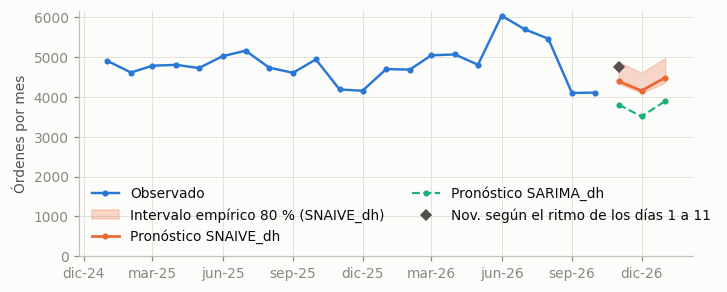

In [16]:
# Contraste con lo ya observado en noviembre de 2026 (ritmo de los primeros días contra los mismos días de 2025)
n_dias = nov_parcial.index[-1].day
obs26 = nov_parcial.ordenes.sum()
obs25 = diario["2025-11-01":"2025-11-%02d" % n_dias].ordenes.sum()
bd26 = np.busday_count("2026-11-01", (nov_parcial.index[-1] + pd.Timedelta(days=1)).date())
bd25 = np.busday_count("2025-11-01", "2025-11-%02d" % (n_dias + 1))
ritmo = (obs26 / bd26) / (obs25 / bd25)
print("Noviembre 1 al %d: 2026 = %d órdenes (%d días hábiles) | 2025 = %d (%d días hábiles)" % (n_dias, obs26, bd26, obs25, bd25))
print("Ritmo por día hábil 2026 / 2025: %.3f" % ritmo)
print("%s de noviembre: %d | ajustado por el ritmo observado: %d" % (MEJOR, fin.loc["2026-11-01", MEJOR], fin.loc["2026-11-01", MEJOR] * ritmo))

fig, ax = plt.subplots(figsize=(7.2, 2.9))
hist = serie["2025-01":]
lo, hi = intervalo(MEJOR)
ax.plot(hist.index, hist.values, color=C["azul"], lw=1.6, marker="o", ms=3, label="Observado")
ax.fill_between(fut, lo, hi, color=C["naranja"], alpha=0.25, label="Intervalo empírico 80 % (" + MEJOR + ")")
ax.plot(fut, fin[MEJOR], color=C["naranja"], lw=1.8, marker="o", ms=3, label="Pronóstico " + MEJOR)
ax.plot(fut, fin["SARIMA_dh"], color=C["aqua"], lw=1.4, marker="o", ms=3, ls="--", label="Pronóstico SARIMA_dh")
ax.plot([fut[0]], [fin.loc[fut[0], MEJOR] * ritmo], marker="D", ms=5, color=C["tinta2"], ls="none",
        label="Nov. según el ritmo de los días 1 a %d" % n_dias)
ax.set(ylabel="Órdenes por mes", ylim=(0, None)); ax.legend(loc="lower left", ncol=2)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3)); ax.xaxis.set_major_formatter(FMT_MES)
fig.savefig("figuras/fig5_pronostico.png"); plt.show()

## 7. Vista diaria (base para la parte 2)

El pronóstico diario a 15 días es la segunda parte del proyecto. Aquí solo se muestra lo que la justifica: el patrón semanal por país en hora de Costa Rica. El lunes de Australia y Nueva Zelanda empieza el domingo por la tarde en Costa Rica (UTC+10/+11 y UTC+12/+13 contra UTC−6), así que sus órdenes del lunes llegan el domingo y sus feriados afectan el día anterior en Costa Rica.

Promedio de órdenes por día de la semana (hora CR), últimas 52 semanas:
        us    ca    au   nz  total
lun  147.4  51.2  18.1  2.6  219.3
mar  164.8  59.8  19.0  1.9  245.5
mié  159.8  61.0  20.6  2.1  243.4
jue  154.0  61.6  17.5  3.3  236.4
vie   81.2  30.9   5.2  0.6  117.8
sáb   12.0   7.0   1.2  0.9   21.2
dom   13.1   7.9  12.9  1.9   35.8
Fuerza de la estacionalidad semanal (STL, período 7): 0.89
Australia y Nueva Zelanda aportan el 41 % de las órdenes del domingo en hora CR


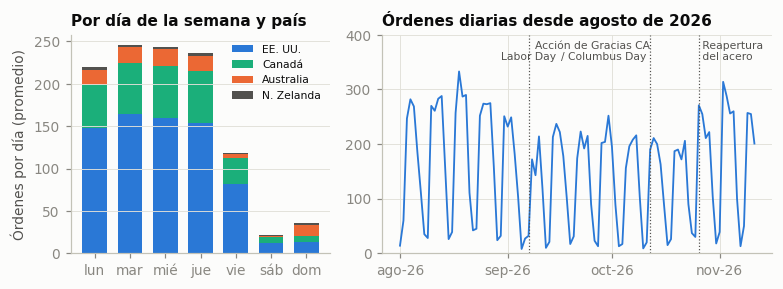

In [17]:
ult = diario[diario.index[-1] - pd.Timedelta(weeks=52) + pd.Timedelta(days=1):]
perfil = ult[PAISES].groupby(ult.index.dayofweek).mean()
dias_sem = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]
print("Promedio de órdenes por día de la semana (hora CR), últimas 52 semanas:")
print(perfil.assign(total=ult.groupby(ult.index.dayofweek).ordenes.mean()).round(1).set_axis(dias_sem).to_string())
print("Fuerza de la estacionalidad semanal (STL, período 7): %.2f" %
      (lambda r: max(0, 1 - np.var(r.resid) / np.var(r.seasonal + r.resid)))(STL(diario.ordenes.astype(float), period=7, robust=True).fit()))
print("Australia y Nueva Zelanda aportan el %.0f %% de las órdenes del domingo en hora CR" %
      (100 * perfil.loc[6, ["au", "nz"]].sum() / perfil.loc[6].sum()))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(7.2, 2.7), gridspec_kw={"width_ratios": [1, 1.5]})
abajo = np.zeros(7)
for p, col, et in [("us", C["azul"], "EE. UU."), ("ca", C["aqua"], "Canadá"), ("au", C["naranja"], "Australia"), ("nz", C["tinta2"], "N. Zelanda")]:
    a1.bar(range(7), perfil[p].values, bottom=abajo, color=col, label=et, width=0.7); abajo += perfil[p].values
a1.set_xticks(range(7)); a1.set_xticklabels(dias_sem); a1.grid(axis="x", visible=False)
a1.set(ylabel="Órdenes por día (promedio)", title="Por día de la semana y país"); a1.legend(loc="upper right", fontsize=7)
tramo = diario["2026-08-01":]
a2.plot(tramo.index, tramo.ordenes, color=C["azul"], lw=1.2)
for f, et, ha in [("2026-09-07", "Labor Day", "center"), ("2026-10-12", "Acción de Gracias CA\n/ Columbus Day ", "right"),
                  ("2026-10-26", " Reapertura\n del acero", "left")]:
    a2.axvline(pd.Timestamp(f), color=C["tinta2"], lw=0.8, ls=":")
    a2.annotate(et, xy=(pd.Timestamp(f), 350), fontsize=7, color=C["tinta2"], ha=ha, va="bottom")
a2.set(title="Órdenes diarias desde agosto de 2026", ylim=(0, 400))
a2.xaxis.set_major_locator(mdates.MonthLocator()); a2.xaxis.set_major_formatter(FMT_MES)
fig.tight_layout(); fig.savefig("figuras/fig6_vista_diaria.png"); plt.show()

## 8. Conclusiones

1. **El mejor modelo mensual es el ingenuo estacional ajustado por días hábiles (SNAIVE_dh).** Tiene el MASE promedio más bajo (0.56) y supera al ingenuo estacional simple en 14 de 20 ventanas (Wilcoxon p = 0.008). Frente a SARIMA_dh (0.63), el segundo, gana en 13 de 20, pero la diferencia no es significativa (p = 0.14).
2. **Ajustar por días hábiles ayuda casi siempre.** Mejora a SNAIVE (0.65 a 0.56), SARIMA (0.70 a 0.63) y AutoETS (0.91 a 0.81). En Chronos-2 la covariable de días hábiles casi no cambia el resultado (0.92 a 0.91).
3. **Los modelos de fundación no superan a las referencias clásicas con esta serie.** TimesFM 2.5 (0.84) y Chronos-2 (0.92) son mejores que el ingenuo (1.09), pero le ganan al ingenuo estacional en 2 o 3 de las 20 ventanas. Con 24 a 43 meses de contexto y un patrón anual estable, repetir el año anterior ya captura casi todo.
4. **Con origen desde marzo de 2026 todos fallan** (MASE entre 1.25 y 2.19): el auge del acero y su pausa fueron decisiones de capacidad que ningún modelo univariado anticipa. Ahí los menos malos son SARIMA_dh (1.25) y Ridge (1.34).
5. **Pronóstico oficial (SNAIVE_dh): 4,396 órdenes en noviembre, 4,156 en diciembre y 4,485 en enero (13,038 en el trimestre).** Lo observado del 1 al 11 de noviembre va 8 % arriba por día hábil respecto de 2025, lo que proyecta cerca de 4,750 en noviembre, dentro del intervalo empírico. SARIMA_dh (11,211) arrastra el nivel bajo de septiembre y octubre, causado por la pausa del acero, y no se adopta.
6. **Para la parte 2 (diario a 15 días):** la estacionalidad semanal es fuerte (0.89) y los países tienen calendarios y husos horarios distintos. En hora de Costa Rica, el lunes de Australia y Nueva Zelanda cae en domingo. El plan es comparar el reparto del pronóstico mensual con un perfil semanal y feriados por país contra modelos diarios directos.